# Knowledge Distillation Experiment: Image Classification (MNIST)

## Experiment Goals:
1. Train a large CNN teacher on MNIST
2. Train a small CNN student using distillation
3. Compare with a control student of the same architecture trained without the teacher, over several seeds
4. Repeat the comparison where the students only get 1,000 training images, after a temperature and alpha sweep on the validation set
5. Analyze performance vs model size tradeoff

The protocol follows Hinton, Vinyals and Dean (2015).
The teacher is trained first and then frozen.
The distilled student and the control student share the architecture, the optimizer, the number of steps, the initial weights and the order of the batches, so the only difference between them is the loss.
A validation split held out from the training set is used while training, and the test set is read once, at the end.

## Setup and Dependencies

In [1]:
import os
# hide tensorflow's c++ start up messages so the saved outputs only show the experiment
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import platform
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from scipy import stats

# python side tensorflow notices, such as the one about gpus on windows, would otherwise land in the outputs
tf.get_logger().setLevel('ERROR')

### Reproducibility

Every random choice below is driven by one of these seeds.
`SEED` fixes the validation split and the teacher, each student arm is trained once per entry of `SEEDS`.

In [2]:
SEED = 0
SEEDS = [0, 1, 2, 3, 4]
# fixed seeds alone do not make tensorflow repeatable, deterministic kernels are needed as well
tf.config.experimental.enable_op_determinism()

In [3]:
print(f"python {platform.python_version()}, tensorflow {tf.__version__}, keras {keras.__version__}, "
      f"numpy {np.__version__}, pandas {pd.__version__}")
print(f"platform: {platform.platform()}, {os.cpu_count()} logical cpus, "
      f"gpus visible: {len(tf.config.list_physical_devices('GPU'))}")
print(f"data and teacher seed: {SEED}, student seeds: {SEEDS}")

python 3.12.15, tensorflow 2.21.0, keras 3.15.1, numpy 2.5.4, pandas 3.0.6
platform: Windows-10-10.0.19045-SP0, 16 logical cpus, gpus visible: 0
data and teacher seed: 0, student seeds: [0, 1, 2, 3, 4]


## Load MNIST Dataset

In [4]:
# mnist: 60k train and 10k test 28x28 grayscale digits, 10 classes
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

# scale to [0, 1] and add the channel axis the conv layers expect
x_train_full = (x_train_full.astype('float32') / 255.0)[..., None]
x_test = (x_test.astype('float32') / 255.0)[..., None]

Hold out 6,000 training images as a validation set.
Everything that is looked at during training uses it, so the test set stays untouched until the final comparison.

In [5]:
perm = np.random.default_rng(SEED).permutation(len(x_train_full))
val_idx, train_idx = perm[:6000], perm[6000:]
x_train, y_train = x_train_full[train_idx], y_train_full[train_idx]
x_val, y_val = x_train_full[val_idx], y_train_full[val_idx]

In [6]:
print(f"training samples: {len(x_train)}")
print(f"validation samples: {len(x_val)}")
print(f"test samples: {len(x_test)}")
print(f"image shape: {x_train.shape[1:]}")

training samples: 54000
validation samples: 6000
test samples: 10000
image shape: (28, 28, 1)


a few training digits with their labels

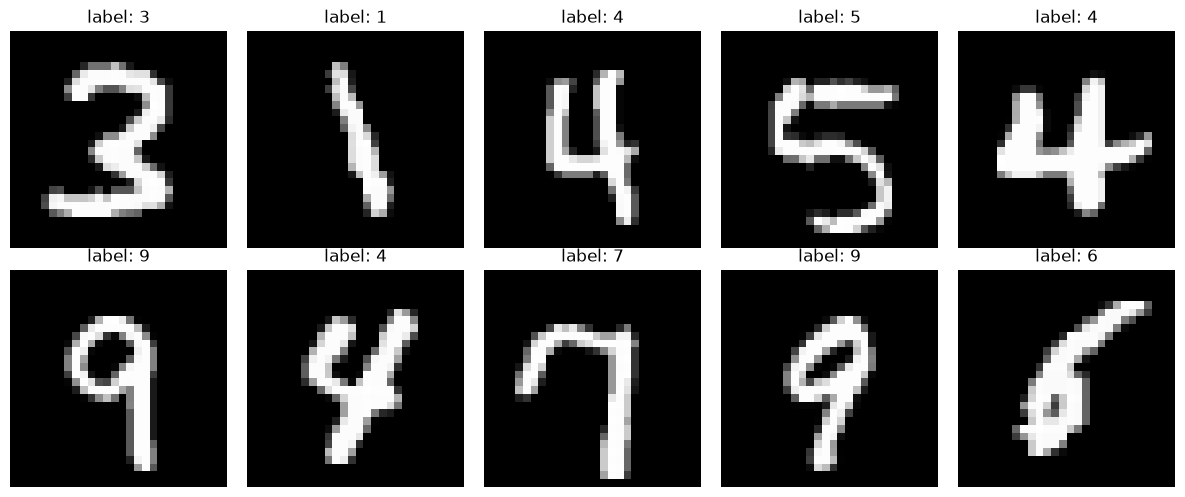

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i].squeeze(), cmap='gray')
    ax.set_title(f'label: {y_train[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Define Teacher and Student Models

Both models end in a plain `Dense(10)` layer, so they output logits.
Distillation softens logits with `softmax(z / T)`.
Applying it to outputs that already went through a softmax would soften probabilities instead.
A probability vector divided by `T = 4` sums to 0.25, so after the second softmax every class lands between 0.097 and 0.125 (computed in the next cell), which says almost nothing about the teacher.

In [8]:
# p / 4 sums to 0.25, both extremes come from a one hot p: the top class gets e^0.25 / (e^0.25 + 9)
# and every other class 1 / (e^0.25 + 9)
e = np.exp(0.25)
print(f"softmax(p / 4) for any probability vector p: every class between {1 / (e + 9):.3f} and {e / (e + 9):.3f}")

softmax(p / 4) for any probability vector p: every class between 0.097 and 0.125


In [9]:
# teacher: a large cnn, only its accuracy matters because it is never deployed
def create_teacher_model():
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),
        keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(128, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(256, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Flatten(),
        keras.layers.Dense(512, activation='relu'),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(256, activation='relu'),
        keras.layers.Dropout(0.5),
        # no softmax: the model emits logits so the distillation loss can soften them with softmax(z / t)
        keras.layers.Dense(10),
    ])
    return model

In [10]:
# student: about 8x fewer parameters than the teacher, the model meant for deployment
def create_student_model():
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),
        keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dropout(0.3),
        # no softmax, as in the teacher
        keras.layers.Dense(10),
    ])
    return model

In [11]:
create_teacher_model().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,683,722 (6.42 MB)

 Trainable params: 1,683,722 (6.42 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
create_student_model().summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       200,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 206,922 (808.29 KB)

 Trainable params: 206,922 (808.29 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
teacher_params = create_teacher_model().count_params()
student_params = create_student_model().count_params()

print("model architecture comparison:")
print(f"teacher parameters: {teacher_params:,}")
print(f"student parameters: {student_params:,}")
print(f"compression ratio: {teacher_params/student_params:.1f}x")
print(f"size reduction: {(1-student_params/teacher_params)*100:.1f}%")

model architecture comparison:
teacher parameters: 1,683,722
student parameters: 206,922
compression ratio: 8.1x
size reduction: 87.7%


## Training Functions

The loss is `alpha * soft + (1 - alpha) * hard`.
The soft term is `KL(softmax(teacher / T) || softmax(student / T))` multiplied by `T^2`, the hard term is the ordinary cross entropy with the labels at `T = 1`.
With `alpha = 0` the loss is plain supervised training, which is how the teacher and the control student are trained.

In [14]:
# distillation loss after hinton, vinyals and dean (2015): alpha weights the soft term, 1 - alpha the hard term
def distillation_loss(y_true, student_logits, teacher_logits, temperature, alpha):
    # hard term at t=1: cross entropy with the true labels keeps the student anchored to the ground truth
    hard = tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=tf.cast(y_true, tf.int32), logits=student_logits))
    if alpha == 0:
        return hard
    # soft term: kl(teacher_t || student_t) on logits, a temperature above 1 exposes how the teacher ranks
    # the wrong classes, log space avoids an epsilon, times t^2 because soft target gradients shrink as 1 / t^2
    teacher_log = tf.nn.log_softmax(teacher_logits / temperature)
    student_log = tf.nn.log_softmax(student_logits / temperature)
    soft = tf.reduce_mean(tf.reduce_sum(tf.exp(teacher_log) * (teacher_log - student_log), axis=1)) * temperature ** 2
    return alpha * soft + (1 - alpha) * hard

Check the TensorFlow loss against `distillation/losses.py`, the NumPy reference that `tests/test_losses.py` covers, on random logits.

In [15]:
sys.path.insert(0, os.path.abspath('..'))
from distillation import losses as reference

rng = np.random.default_rng(SEED)
check_student, check_teacher = rng.normal(0, 3, (64, 10)), rng.normal(0, 3, (64, 10))
check_labels = rng.integers(0, 10, 64)
for check_t, check_alpha in [(1.0, 0.5), (4.0, 0.7), (8.0, 0.9), (4.0, 0.0)]:
    ours = float(distillation_loss(check_labels, tf.constant(check_student, tf.float32),
                                   tf.constant(check_teacher, tf.float32), check_t, check_alpha))
    ref = reference.distillation_loss(check_labels, check_student, check_teacher, check_t, check_alpha)
    print(f"t={check_t}, alpha={check_alpha}: tensorflow {ours:.6f}, reference {ref:.6f}, difference {abs(ours - ref):.1e}")

t=1.0, alpha=0.5: tensorflow 4.004925, reference 4.004925, difference 2.4e-07
t=4.0, alpha=0.7: tensorflow 6.196318, reference 6.196318, difference 3.0e-07
t=8.0, alpha=0.9: tensorflow 7.151145, reference 7.151144, difference 6.1e-08
t=4.0, alpha=0.0: tensorflow 4.077404, reference 4.077404, difference 1.4e-07


One training step, compiled with `tf.function`.
A custom step is needed because `fit()` has no hook for feeding the teacher's outputs into the loss.

In [16]:
def make_train_step(model, optimizer, temperature, alpha):
    @tf.function(reduce_retracing=True)
    def train_step(x, y, teacher_logits):
        with tf.GradientTape() as tape:
            logits = model(x, training=True)
            loss = distillation_loss(y, logits, teacher_logits, temperature, alpha)
        # only this model's variables get gradients, which is what keeps the teacher frozen
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        return loss
    return train_step

In [17]:
def accuracy(model, x, y):
    # inference mode turns dropout off, argmax of the logits is the same at every temperature
    logits = model.predict(x, batch_size=1000, verbose=0)
    return float(np.mean(np.argmax(logits, axis=1) == y))

The same loop trains the teacher, the control student and the distilled student.
For a given seed the control and the distilled student start from the same weights and see the batches in the same order.

In [18]:
def train(model, x, y, teacher_logits=None, temperature=1.0, alpha=0.0, epochs=10,
          batch_size=128, seed=0, eval_every=1):
    optimizer = keras.optimizers.Adam(learning_rate=0.001)
    train_step = make_train_step(model, optimizer, temperature, alpha)
    # one generator per run, so the batch order depends on the seed and nothing else
    rng = np.random.default_rng(seed)
    history = {'epoch': [], 'val_acc': []}
    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(x))
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            batch_teacher = None if teacher_logits is None else teacher_logits[idx]
            train_step(x[idx], y[idx], batch_teacher)
        if epoch % eval_every == 0 or epoch == epochs:
            history['epoch'].append(epoch)
            history['val_acc'].append(accuracy(model, x_val, y_val))
    return history

In [19]:
def new_model(create, seed):
    # the global seed fixes the initial weights and the dropout masks of the model built next
    keras.utils.set_random_seed(seed)
    return create()

In [20]:
def train_student(arm, seed, x, y, teacher_logits, temperature, alpha, epochs, eval_every=1):
    # the control gets no teacher and alpha=0, everything else is identical to the distilled run
    model = new_model(create_student_model, seed)
    if arm == 'control':
        history = train(model, x, y, epochs=epochs, seed=seed, eval_every=eval_every)
    else:
        history = train(model, x, y, teacher_logits=teacher_logits, temperature=temperature,
                        alpha=alpha, epochs=epochs, seed=seed, eval_every=eval_every)
    return model, history

## Train Teacher Model

In [21]:
# the teacher is trained first, on hard labels only
t0 = time.time()
teacher = new_model(create_teacher_model, SEED)
teacher_history = train(teacher, x_train, y_train, epochs=10, seed=SEED)
print(f"teacher trained in {time.time() - t0:.0f} s")
print(f"teacher validation accuracy by epoch: {np.round(teacher_history['val_acc'], 4).tolist()}")

teacher trained in 271 s
teacher validation accuracy by epoch: [0.9805, 0.9863, 0.9907, 0.99, 0.9907, 0.9913, 0.9912, 0.9902, 0.992, 0.9898]


Freeze the teacher and compute its logits for every training image once.
There is no data augmentation, so these are exactly the logits the teacher would produce batch by batch.

In [22]:
teacher.trainable = False
teacher_train_logits = teacher.predict(x_train, batch_size=1000, verbose=0)
print(f"teacher logits: {teacher_train_logits.shape}")

teacher logits: (54000, 10)


### What the student is shown

The training image the teacher is least sure about, and the teacher's distribution over the ten digits at `T = 1` and `T = 4`.
The last panel is what the old version of this notebook distilled from: a softmax applied twice, which is nearly flat.

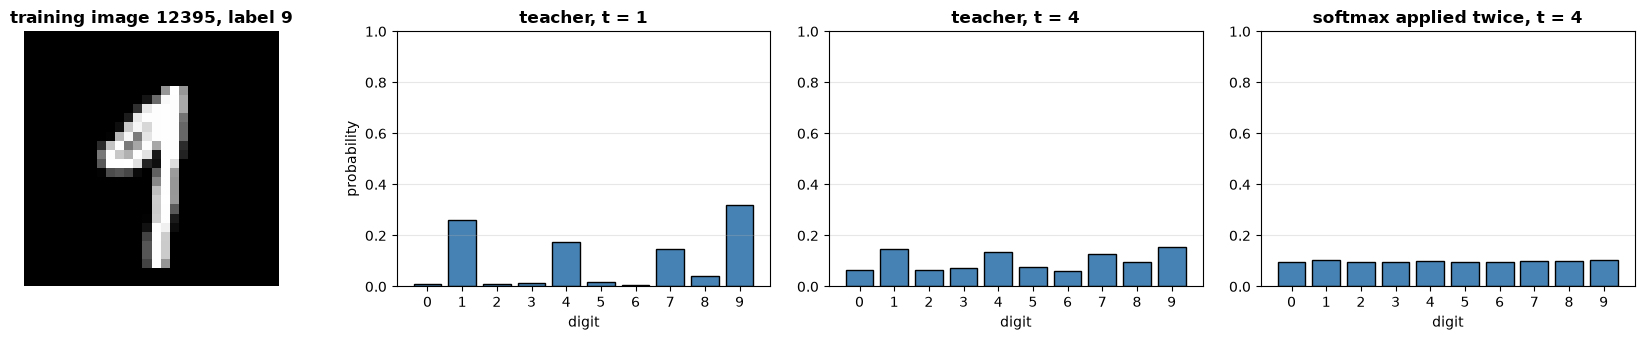

In [23]:
teacher_probs = tf.nn.softmax(teacher_train_logits).numpy()
example = int(np.argmin(teacher_probs.max(axis=1)))
panels = [
    ('teacher, t = 1', teacher_probs[example]),
    ('teacher, t = 4', tf.nn.softmax(teacher_train_logits[example] / 4).numpy()),
    ('softmax applied twice, t = 4', tf.nn.softmax(teacher_probs[example] / 4).numpy()),
]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
axes[0].imshow(x_train[example].squeeze(), cmap='gray')
axes[0].set_title(f'training image {example}, label {y_train[example]}', fontweight='bold')
axes[0].axis('off')
for ax, (title, probs) in zip(axes[1:], panels):
    ax.bar(range(10), probs, color='steelblue', edgecolor='black')
    ax.set_title(title, fontweight='bold')
    ax.set_xticks(range(10))
    ax.set_xlabel('digit')
    ax.set_ylim(0, 1)
    ax.grid(True, axis='y', alpha=0.3)
axes[1].set_ylabel('probability')
plt.tight_layout()
plt.show()

## Train the Students

Each arm is trained once per seed.
`T = 4` and `alpha = 0.7` are the values this notebook has always used, fixed before any results were seen.

In [24]:
temperature = 4.0
alpha = 0.7
epochs = 10

In [25]:
full_runs = {'control': [], 'distilled': []}
t0 = time.time()
for seed in SEEDS:
    for arm in full_runs:
        model, history = train_student(arm, seed, x_train, y_train, teacher_train_logits,
                                       temperature, alpha, epochs)
        full_runs[arm].append({'seed': seed, 'model': model, 'history': history})
        print(f"seed {seed}, {arm}: final validation accuracy {history['val_acc'][-1]:.4f}")
print(f"{len(SEEDS) * 2} student runs in {(time.time() - t0) / 60:.1f} min")

seed 0, control: final validation accuracy 0.9900


seed 0, distilled: final validation accuracy 0.9883


seed 1, control: final validation accuracy 0.9900


seed 1, distilled: final validation accuracy 0.9883


seed 2, control: final validation accuracy 0.9883


seed 2, distilled: final validation accuracy 0.9887


seed 3, control: final validation accuracy 0.9880


seed 3, distilled: final validation accuracy 0.9878


seed 4, control: final validation accuracy 0.9880


seed 4, distilled: final validation accuracy 0.9883
10 student runs in 5.8 min


## A Setting With Headroom: 1,000 Training Images

With 54,000 labelled images both students get close to the teacher, which leaves the soft targets little to add.
Here the students only see 100 images per class, while the teacher is the same one trained on all 54,000.
This is the situation where a large model already exists and the data available for the small one is limited.
Hinton et al. (2015, section 6) report the same pattern on speech, where soft targets let a model trained on 3% of the data generalise far better than hard targets.

In [26]:
rng = np.random.default_rng(SEED)
small_idx = np.concatenate([rng.choice(np.flatnonzero(y_train == digit), 100, replace=False) for digit in range(10)])
x_small, y_small = x_train[small_idx], y_train[small_idx]
teacher_small_logits = teacher_train_logits[small_idx]
print(f"small training set: {len(x_small)} images, per class counts {np.bincount(y_small).tolist()}")

small training set: 1000 images, per class counts [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]


### Temperature and alpha sweep

Every pair of `T` and `alpha` is trained with three seeds and scored on the validation set, never on the test set.
With 8 batches per epoch, 50 epochs is 400 steps.

In [27]:
TEMPERATURES = [1.0, 2.0, 4.0, 8.0]
ALPHAS = [0.5, 0.7, 0.9]
SWEEP_SEEDS = SEEDS[:3]
small_epochs = 50

In [28]:
sweep_rows = []
t0 = time.time()
for sweep_t in TEMPERATURES:
    for sweep_alpha in ALPHAS:
        for seed in SWEEP_SEEDS:
            _, history = train_student('distilled', seed, x_small, y_small, teacher_small_logits,
                                       sweep_t, sweep_alpha, small_epochs, eval_every=small_epochs)
            sweep_rows.append({'temperature': sweep_t, 'alpha': sweep_alpha, 'seed': seed,
                               'val_acc': history['val_acc'][-1] * 100})
for seed in SWEEP_SEEDS:
    _, history = train_student('control', seed, x_small, y_small, None, 1.0, 0.0, small_epochs, eval_every=small_epochs)
    sweep_rows.append({'temperature': float('nan'), 'alpha': 0.0, 'seed': seed, 'val_acc': history['val_acc'][-1] * 100})
sweep = pd.DataFrame(sweep_rows)
print(f"{len(sweep)} sweep runs in {(time.time() - t0) / 60:.1f} min")

39 sweep runs in 3.4 min


In [29]:
distilled_sweep = sweep[sweep['alpha'] > 0]
sweep_mean = distilled_sweep.pivot_table(index='temperature', columns='alpha', values='val_acc', aggfunc='mean')
sweep_std = distilled_sweep.pivot_table(index='temperature', columns='alpha', values='val_acc', aggfunc='std')
control_val = sweep[sweep['alpha'] == 0]['val_acc']
print("validation accuracy (%), mean over 3 seeds, rows are t, columns are alpha")
print(sweep_mean.round(2).to_string())
print("\nstandard deviation over the same seeds")
print(sweep_std.round(2).to_string())
print(f"\ncontrol student on the same {len(x_small):,} images: {control_val.mean():.2f} +/- {control_val.std():.2f}")

validation accuracy (%), mean over 3 seeds, rows are t, columns are alpha
alpha          0.5    0.7    0.9
temperature                     
1.0          94.63  94.52  94.61
2.0          94.58  94.64  94.62
4.0          95.04  95.08  95.13
8.0          95.44  95.37  95.37

standard deviation over the same seeds
alpha         0.5   0.7   0.9
temperature                  
1.0          0.14  0.27  0.11
2.0          0.26  0.23  0.19
4.0          0.24  0.14  0.14
8.0          0.14  0.19  0.14

control student on the same 1,000 images: 94.34 +/- 0.52


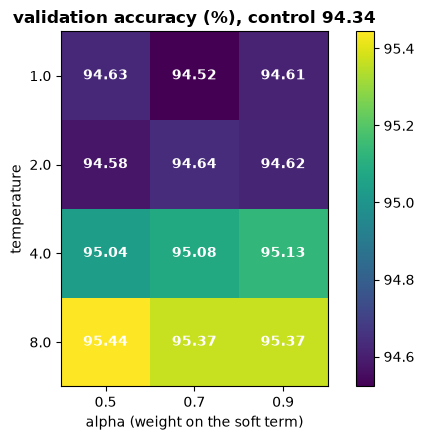

In [30]:
fig, ax = plt.subplots(figsize=(6, 4.5))
image = ax.imshow(sweep_mean.values, cmap='viridis')
ax.set_xticks(range(len(ALPHAS)), [str(a) for a in sweep_mean.columns])
ax.set_yticks(range(len(TEMPERATURES)), [str(v) for v in sweep_mean.index])
ax.set_xlabel('alpha (weight on the soft term)')
ax.set_ylabel('temperature')
for i in range(sweep_mean.shape[0]):
    for j in range(sweep_mean.shape[1]):
        ax.text(j, i, f'{sweep_mean.values[i, j]:.2f}', ha='center', va='center', color='white', fontweight='bold')
ax.set_title(f'validation accuracy (%), control {control_val.mean():.2f}', fontweight='bold')
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

In [31]:
# the pair with the best mean validation accuracy is carried to the test comparison
best_t, best_alpha = sweep_mean.stack().idxmax()
print(f"selected on validation: t = {best_t}, alpha = {best_alpha}")

selected on validation: t = 8.0, alpha = 0.5


### Students on 1,000 images

Both arms with the selected `T` and `alpha`, over all five seeds, validation accuracy logged every 5 epochs.

In [32]:
small_runs = {'control': [], 'distilled': []}
t0 = time.time()
for seed in SEEDS:
    for arm in small_runs:
        model, history = train_student(arm, seed, x_small, y_small, teacher_small_logits,
                                       best_t, best_alpha, small_epochs, eval_every=5)
        small_runs[arm].append({'seed': seed, 'model': model, 'history': history})
        print(f"seed {seed}, {arm}: final validation accuracy {history['val_acc'][-1]:.4f}")
print(f"{len(SEEDS) * 2} student runs in {(time.time() - t0) / 60:.1f} min")

seed 0, control: final validation accuracy 0.9443


seed 0, distilled: final validation accuracy 0.9528


seed 1, control: final validation accuracy 0.9482


seed 1, distilled: final validation accuracy 0.9555


seed 2, control: final validation accuracy 0.9378


seed 2, distilled: final validation accuracy 0.9550


seed 3, control: final validation accuracy 0.9473


seed 3, distilled: final validation accuracy 0.9577


seed 4, control: final validation accuracy 0.9455


seed 4, distilled: final validation accuracy 0.9560
10 student runs in 0.9 min


## Results Comparison

Validation accuracy during training, mean and standard deviation over the seeds, all models evaluated with dropout off.
The teacher's curve is shown in the left panel only, it was trained on the full set in both cases.

In [33]:
RESULTS_DIR = os.path.join('..', 'results', 'image_classification')
ARM_STYLE = {'control': ('student (control)', 'tab:gray', '^'), 'distilled': ('student (distilled)', 'tab:green', 's')}

In [34]:
def plot_val_curves(ax, runs, title):
    for arm, (label, color, marker) in ARM_STYLE.items():
        epochs_seen = runs[arm][0]['history']['epoch']
        curves = np.array([run['history']['val_acc'] for run in runs[arm]]) * 100
        mean, std = curves.mean(axis=0), curves.std(axis=0, ddof=1)
        ax.plot(epochs_seen, mean, marker=marker, color=color, label=f'{label}, {len(curves)} seeds')
        ax.fill_between(epochs_seen, mean - std, mean + std, color=color, alpha=0.2)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('epoch')
    ax.set_ylabel('validation accuracy (%)')
    ax.grid(True, alpha=0.3)

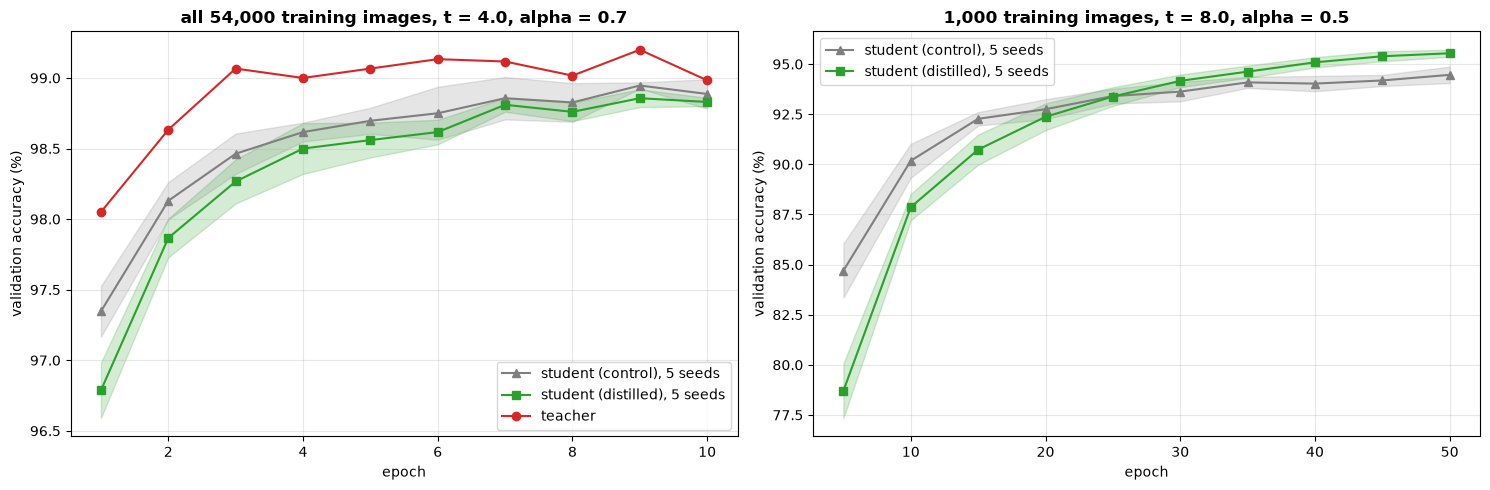

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_val_curves(axes[0], full_runs, f'all {len(x_train):,} training images, t = {temperature}, alpha = {alpha}')
axes[0].plot(teacher_history['epoch'], np.array(teacher_history['val_acc']) * 100, color='tab:red', marker='o', label='teacher')
plot_val_curves(axes[1], small_runs, f'{len(x_small):,} training images, t = {best_t}, alpha = {best_alpha}')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'distillation_results.png'), dpi=150, bbox_inches='tight')
plt.show()

The test set is read here for the first time, once per model.

In [36]:
teacher_test_acc = accuracy(teacher, x_test, y_test) * 100
for runs in [full_runs, small_runs]:
    for arm in runs:
        for run in runs[arm]:
            run['test_acc'] = accuracy(run['model'], x_test, y_test) * 100

In [37]:
def per_seed_table(runs):
    table = pd.DataFrame({arm: [run['test_acc'] for run in runs[arm]] for arm in runs},
                         index=pd.Index(SEEDS, name='seed'))
    table['distilled - control'] = table['distilled'] - table['control']
    return table

In [38]:
per_seed = per_seed_table(full_runs)
per_seed_small = per_seed_table(small_runs)
print(f"test accuracy (%) per seed, {len(x_train):,} training images")
print(per_seed.round(2).to_string())
print(f"\ntest accuracy (%) per seed, {len(x_small):,} training images")
print(per_seed_small.round(2).to_string())

test accuracy (%) per seed, 54,000 training images
      control  distilled  distilled - control
seed                                         
0       99.13      98.94                -0.19
1       99.12      98.93                -0.19
2       99.15      99.01                -0.14
3       99.01      99.06                 0.05
4       98.98      98.99                 0.01

test accuracy (%) per seed, 1,000 training images
      control  distilled  distilled - control
seed                                         
0       94.96      95.55                 0.59
1       95.12      95.69                 0.57
2       94.74      96.02                 1.28
3       95.27      96.00                 0.73
4       95.24      95.89                 0.65


### Results table

In [39]:
def model_size_mb(params):
    # float32 weights, 4 bytes each
    return params * 4 / 1e6

def result_row(name, train_images, params, accs):
    accs = np.atleast_1d(accs)
    return {'model': name, 'train images': train_images, 'parameters': params,
            'size (MB)': round(model_size_mb(params), 2), 'runs': len(accs),
            'test acc mean (%)': round(float(np.mean(accs)), 2),
            'test acc std': round(float(np.std(accs, ddof=1)), 2) if len(accs) > 1 else float('nan')}

In [40]:
results = pd.DataFrame([
    result_row('teacher', len(x_train), teacher_params, teacher_test_acc),
    result_row('student, control', len(x_train), student_params, per_seed['control']),
    result_row(f'student, distilled (t={temperature}, alpha={alpha})', len(x_train), student_params, per_seed['distilled']),
    result_row('student, control', len(x_small), student_params, per_seed_small['control']),
    result_row(f'student, distilled (t={best_t}, alpha={best_alpha})', len(x_small), student_params, per_seed_small['distilled']),
])
print(results.to_string(index=False))

                                model  train images  parameters  size (MB)  runs  test acc mean (%)  test acc std
                              teacher         54000     1683722       6.73     1              99.10           NaN
                     student, control         54000      206922       0.83     5              99.08          0.08
student, distilled (t=4.0, alpha=0.7)         54000      206922       0.83     5              98.99          0.05
                     student, control          1000      206922       0.83     5              95.07          0.22
student, distilled (t=8.0, alpha=0.5)          1000      206922       0.83     5              95.83          0.20


The two students share the seed, so the per seed differences are paired.
A paired t test over the seeds says whether the mean difference is distinguishable from seed noise.

In [41]:
def paired_summary(control, distilled):
    diff = np.asarray(distilled) - np.asarray(control)
    test = stats.ttest_rel(distilled, control)
    print(f"distilled minus control: {diff.mean():+.2f} +/- {diff.std(ddof=1):.2f} percentage points "
          f"(mean +/- std over {len(diff)} seeds), distilled ahead on {(diff > 0).sum()} of {len(diff)} seeds, "
          f"paired t test p = {test.pvalue:.3f}")

In [42]:
print(f"{len(x_train):,} training images:")
paired_summary(per_seed['control'], per_seed['distilled'])
print(f"\n{len(x_small):,} training images:")
paired_summary(per_seed_small['control'], per_seed_small['distilled'])
print(f"model size reduction: {(1 - student_params / teacher_params) * 100:.1f}%")

54,000 training images:
distilled minus control: -0.09 +/- 0.11 percentage points (mean +/- std over 5 seeds), distilled ahead on 2 of 5 seeds, paired t test p = 0.146

1,000 training images:
distilled minus control: +0.76 +/- 0.30 percentage points (mean +/- std over 5 seeds), distilled ahead on 5 of 5 seeds, paired t test p = 0.004
model size reduction: 87.7%


## Inference Speed Comparison

In [43]:
# wall clock latency per batch, the deployment cost a smaller student is meant to cut
def measure_inference_ms(model, x, batch_size=128, repeats=50):
    forward = tf.function(lambda batch: model(batch, training=False))
    batch = tf.constant(x[:batch_size])
    # the first call traces the graph, keep it out of the timing
    forward(batch)
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        forward(batch).numpy()
        times.append(time.perf_counter() - start)
    # the median is robust to the occasional scheduler hiccup
    return float(np.median(times) * 1000)

In [44]:
teacher_time = measure_inference_ms(teacher, x_test)
student_time = measure_inference_ms(full_runs['distilled'][0]['model'], x_test)

In [45]:
print("inference speed comparison (median over 50 batches of 128):")
print(f"teacher inference time: {teacher_time:.2f} ms/batch")
print(f"student inference time: {student_time:.2f} ms/batch")
print(f"speedup: {teacher_time/student_time:.2f}x")

inference speed comparison (median over 50 batches of 128):
teacher inference time: 18.22 ms/batch
student inference time: 2.19 ms/batch
speedup: 8.31x


## Visualize Predictions

The first five test images on which the two seed 0 students trained on 1,000 images disagree.
This is a qualitative look, the accuracy comparison above is the measurement.

In [46]:
# the first test images where the two seed 0 students trained on 1,000 images disagree
shown = {'teacher': teacher, 'distilled': small_runs['distilled'][0]['model'], 'control': small_runs['control'][0]['model']}
all_predictions = {name: np.argmax(model.predict(x_test, batch_size=1000, verbose=0), axis=1) for name, model in shown.items()}
disagree = np.flatnonzero(all_predictions['distilled'] != all_predictions['control'])[:5]
test_images, test_labels = x_test[disagree], y_test[disagree]
predictions = {name: preds[disagree] for name, preds in all_predictions.items()}
print(f"the seed 0 students disagree on {len(np.flatnonzero(all_predictions['distilled'] != all_predictions['control']))} of {len(x_test)} test images")

the seed 0 students disagree on 310 of 10000 test images


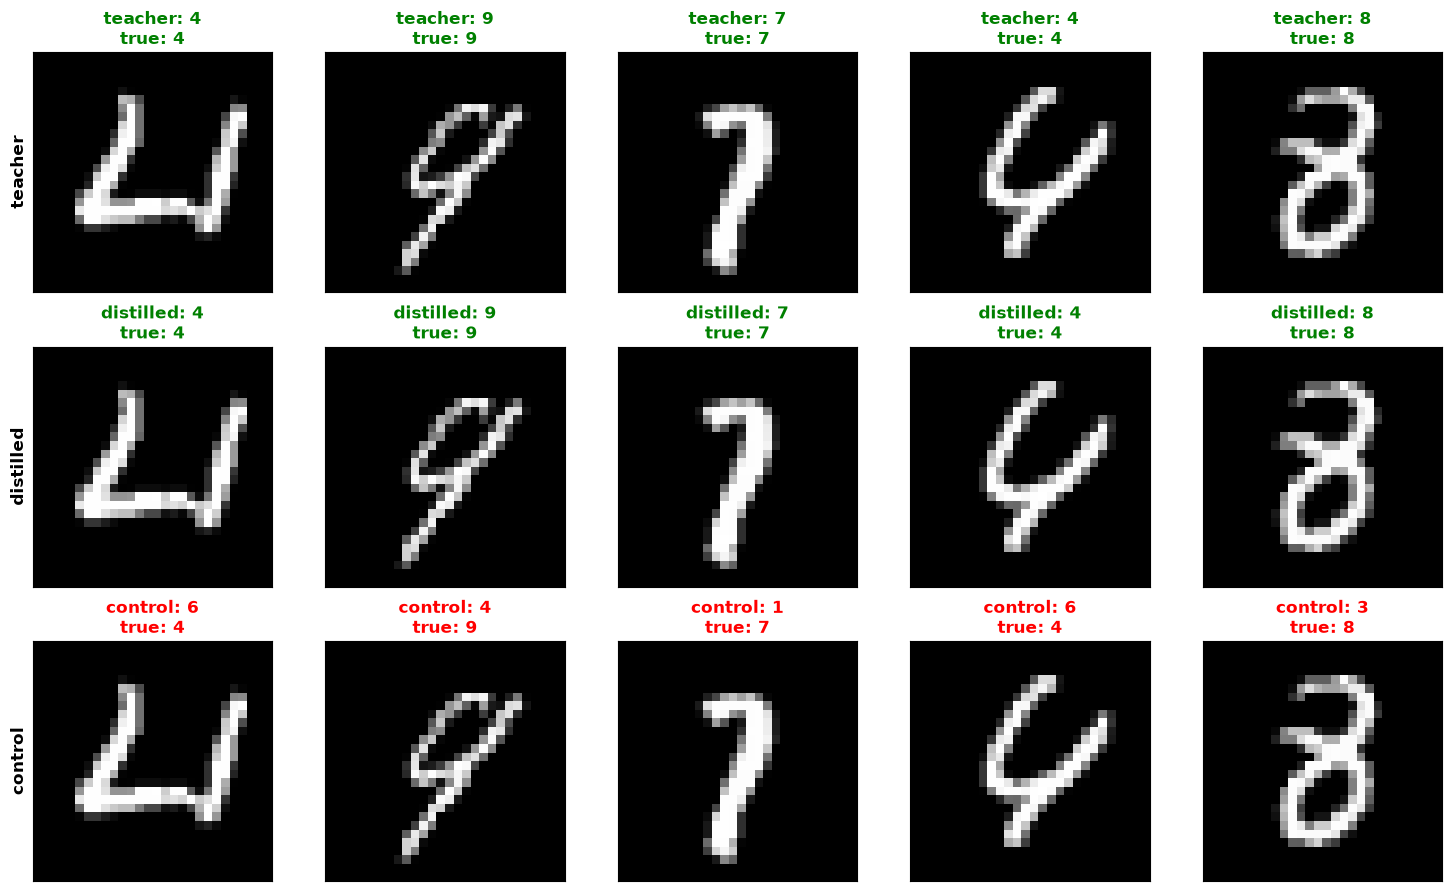

In [47]:
rows = list(predictions.items())
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for row, (name, preds) in enumerate(rows):
    for i in range(5):
        ax = axes[row, i]
        ax.imshow(test_images[i].squeeze(), cmap='gray')
        # hide ticks but keep the axis, axis('off') would also hide the row label
        ax.set_xticks([])
        ax.set_yticks([])
        color = 'green' if preds[i] == test_labels[i] else 'red'
        ax.set_title(f'{name}: {preds[i]}\ntrue: {test_labels[i]}', color=color, fontweight='bold')
    axes[row, 0].set_ylabel(name, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'prediction_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()